In [26]:
#importing all the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Working with pandas lirary

In [27]:
# working with pandas library

# Loading our dataset

df=pd.read_csv("../data/ethiopia.csv")

# Viewing the first 5 records of our dataset
df.head()

,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,T2M_RANGE,PRECTOTCORR,RH2M,WS2M,WS2M_MAX,PS,QV2M
0,2015,1,11.73,22.75,3.44,19.31,0.0,41.79,2.73,5.07,77.13,4.00
1,2015,2,12.30,24.01,4.09,19.92,0.0,33.29,2.39,4.19,77.14,3.35
2,2015,3,12.49,24.17,3.97,20.20,0.0,33.83,1.77,2.76,77.11,3.43
3,2015,4,14.08,23.78,6.90,16.88,0.0,38.84,0.87,1.28,77.07,4.60
4,2015,5,14.06,23.15,7.32,15.83,0.0,47.07,1.34,2.14,77.01,5.58


In [28]:
# Get quick statistical summaries (mean, min, max) of columns
# like Temperature (T2M) and Rainfall (PRECTOTCORR)
print(df[["T2M", "T2M_MAX", "PRECTOTCORR"]].describe())

              T2M      T2M_MAX  PRECTOTCORR
count  4108.00000  4108.000000  4108.000000
mean     16.06850    23.199175     3.633795
std       1.89805     2.751471     6.289061
min      10.03000    15.650000     0.000000
25%      14.82000    21.110000     0.020000
50%      16.04000    22.740000     0.820000
75%      17.36000    25.170000     4.580000
max      21.53000    30.930000    82.300000


In [29]:
#adding a country column to our dataset

df["country"]="Ethiopia"
df.head()

,YEAR,DOY,T2M,T2M_MAX,T2M_MIN,T2M_RANGE,PRECTOTCORR,RH2M,WS2M,WS2M_MAX,PS,QV2M,country
0,2015,1,11.73,22.75,3.44,19.31,0.0,41.79,2.73,5.07,77.13,4.00,Ethiopia
1,2015,2,12.30,24.01,4.09,19.92,0.0,33.29,2.39,4.19,77.14,3.35,Ethiopia
2,2015,3,12.49,24.17,3.97,20.20,0.0,33.83,1.77,2.76,77.11,3.43,Ethiopia
3,2015,4,14.08,23.78,6.90,16.88,0.0,38.84,0.87,1.28,77.07,4.60,Ethiopia
4,2015,5,14.06,23.15,7.32,15.83,0.0,47.07,1.34,2.14,77.01,5.58,Ethiopia


In [30]:
#Filtering rows to find days where it actually rained (Rainfall > 0)

rainy_days=df[df["PRECTOTCORR"]>0]
print(rainy_days)

      YEAR  DOY    T2M  T2M_MAX  T2M_MIN  T2M_RANGE  PRECTOTCORR   RH2M  WS2M  \
9     2015   10  14.25    22.48     7.72      14.76         0.04  53.11  1.93   
10    2015   11  13.98    21.95     6.77      15.18         0.07  70.50  2.39   
11    2015   12  14.27    21.59     9.19      12.40         0.04  73.51  2.96   
12    2015   13  13.75    21.64     8.14      13.50         0.02  70.99  2.89   
16    2015   17  14.63    24.45     6.39      18.06         0.01  61.57  2.18   
...    ...  ...    ...      ...      ...        ...          ...    ...   ...   
4103  2026   86  16.99    24.29    11.80      12.49         5.27  73.87  1.79   
4104  2026   87  15.29    19.58    12.08       7.50         6.46  80.85  1.13   
4105  2026   88  16.28    22.34    11.69      10.65         9.53  77.96  1.30   
4106  2026   89  17.66    25.31    11.08      14.23         0.85  68.88  2.02   
4107  2026   90  18.25    26.36    12.14      14.22         0.40  63.95  2.18   

      WS2M_MAX     PS   QV2

In [31]:
#Group data by YEAR to see the average humidity (RH2M) for each year

yearly_humidity = df.groupby("YEAR")["RH2M"].mean()
print(yearly_humidity)

YEAR
2015    63.213808
2016    69.873142
2017    66.367918
2018    68.323288
2019    69.407726
2020    71.343197
2021    66.888247
2022    68.020493
2023    71.988110
2024    73.088661
2025    67.073863
2026    55.759889
Name: RH2M, dtype: float64


Working with numpy library

In [32]:
#Working with numpy library

# 1. Data Type Conversion
# extracting the underlying raw data array 

max_temps = df["T2M_MAX"].to_numpy()

print(max_temps)

[22.75 24.01 24.17 ... 22.34 25.31 26.36]


In [35]:
# 2. Vectorized Centering: computing arithmetic averages directly 

avg_max_temp= np.mean(max_temps)
print(f"The average max temperature: {avg_max_temp}")

The average max temperature: 23.199174780915286


In [38]:
#3. extreme optimization search 
#minimum and maximum value searching from a column

max_T2M=df["T2M"].min()
min_T2M=df["T2M"].max()

print(f"maximum mean annual temperature is: {max_T2M} degree celcius")
print(f"minimum mean annual temperature is: {min_T2M} degree celcius")


maximum mean annual temperature is: 10.03 degree celcius
minimum mean annual temperature is: 21.53 degree celcius


In [ ]:
# 4. Application of algebric operation

temp_fahrenheit = (df["T2M"].to_numpy() * 9 / 5) + 32
df["T2M in Fahrenheit"]=temp_fahrenheit
df.groupby("T2M")["T2M in Fahrenheit"].unique()

T2M
10.03    [50.054]
10.08    [50.144]
10.28    [50.504]
10.42    [50.756]
10.44    [50.792]
           ...   
21.22    [70.196]
21.31    [70.358]
21.39    [70.502]
21.49    [70.682]
21.53    [70.754]
Name: T2M in Fahrenheit, Length: 861, dtype: object

Working with matplot library

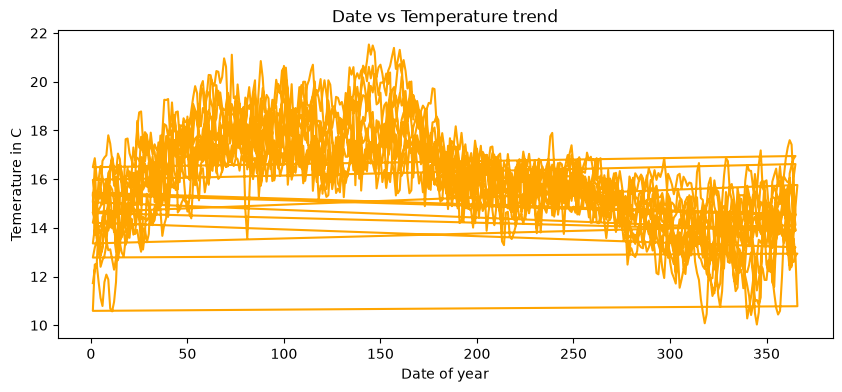

In [ ]:
#Working with matplot library

1. #plotting basic graph
x=df["DOY"]
y=df["T2M"]

plt.figure(figsize=(10, 4))

plt.plot(x, y, color="orange")
plt.title("Date vs Temperature trend")
plt.xlabel("Date of year")
plt.ylabel("Temerature in C")
plt.show()

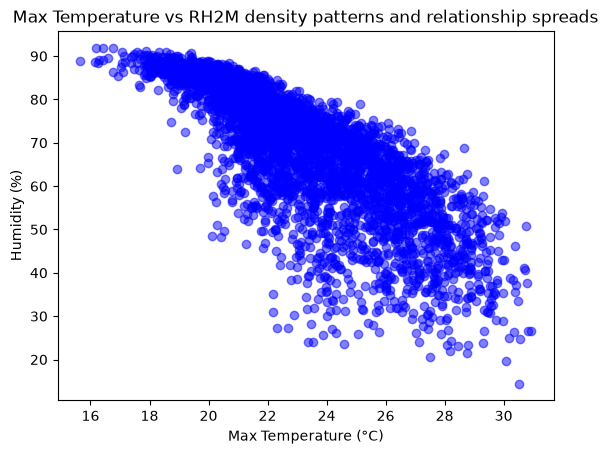

In [58]:
#Distribution plot 
maxtemp=df["T2M_MAX"]
humidity=df["RH2M"]
plt.scatter(maxtemp, humidity, color="blue", alpha=0.5)
plt.title("Max Temperature vs RH2M density patterns and relationship spreads")
plt.xlabel("Max Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.show()

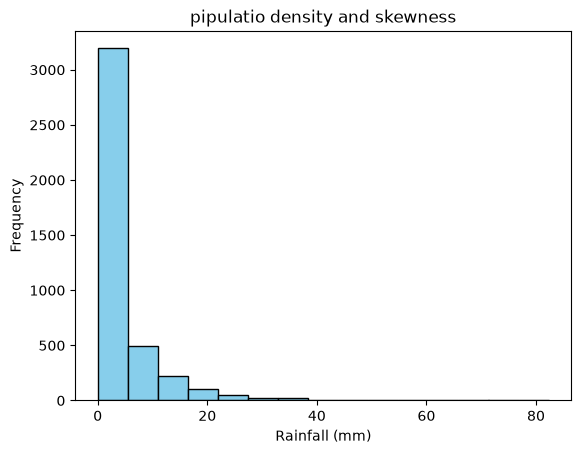

In [59]:
# Frequency bind analysis
rainfall=df["PRECTOTCORR"]
plt.hist(rainfall, bins=15, color="skyblue", edgecolor="black")
plt.title("pipulatio density and skewness")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.show()

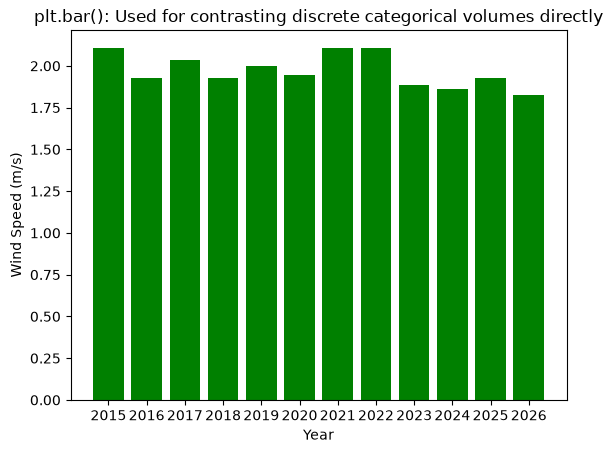

In [60]:
#4 discrete metric visuals

yearly_wind = df.groupby("YEAR")["WS2M"].mean()
plt.bar(yearly_wind.index.astype(str), yearly_wind.values, color="green")
plt.title("plt.bar(): Used for contrasting discrete categorical volumes directly")
plt.xlabel("Year")
plt.ylabel("Wind Speed (m/s)")
plt.show()

Working with seaborn library

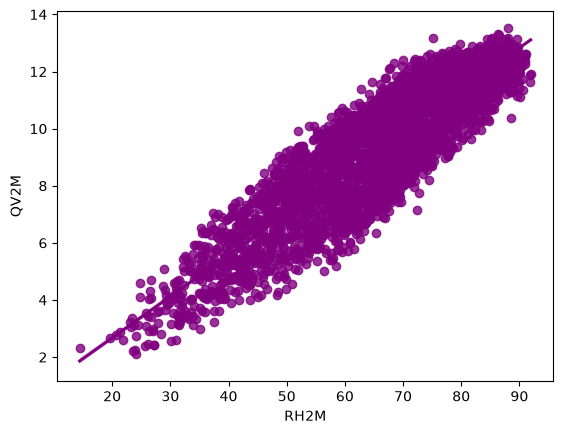

In [61]:
# We use sns.regplot() in order to create a scatter plot of RH2M and QV2M while automatically 
# fitting a linear regression trendline over the points.
sns.regplot(x="RH2M", y="QV2M", data=df, color="purple")
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_8136\3558143183.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="YEAR", y="T2M_MAX", data=df, palette="Set2")


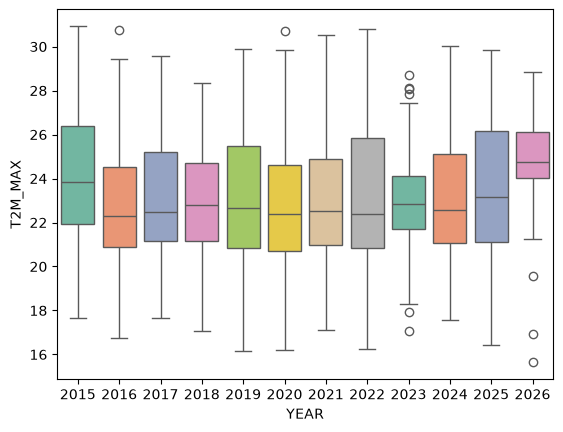

In [62]:
# We use sns.boxplot() in order to display the 5-number summary metrics of T2M_MAX grouped by YEAR and automatically isolate outlier data points.
sns.boxplot(x="YEAR", y="T2M_MAX", data=df, palette="Set2")
plt.show()


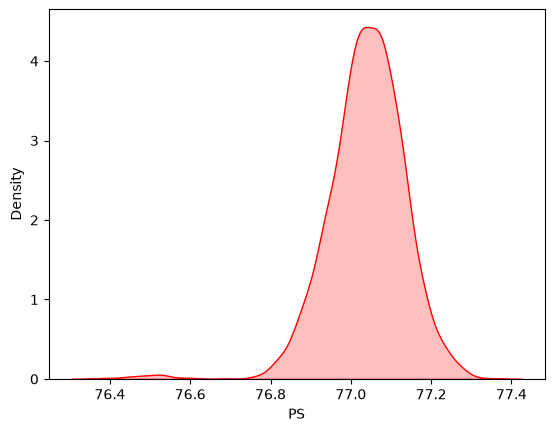

In [63]:
# We use sns.kdeplot() in order to generate a smoothed probability density curve of the surface pressure column PS instead of a blocky histogram.
sns.kdeplot(df["PS"], fill=True, color="red")
plt.show()

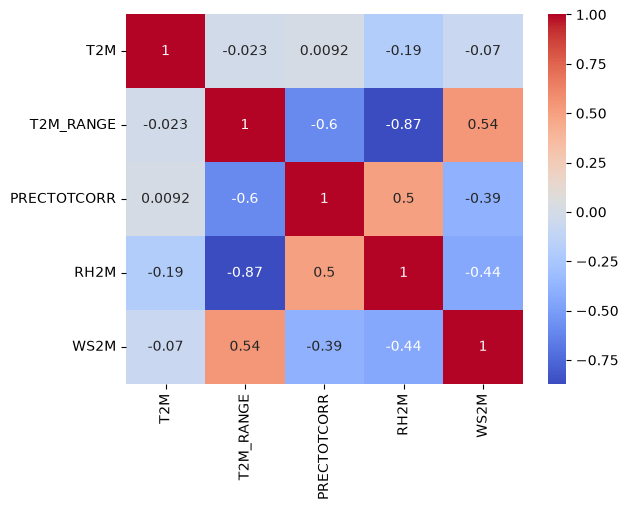

In [64]:
# We use sns.heatmap() in order to transform a calculated correlation matrix of multiple weather metrics into an easy-to-read, color-coded grid.
weather_metrics = df[["T2M", "T2M_RANGE", "PRECTOTCORR", "RH2M", "WS2M"]]
sns.heatmap(weather_metrics.corr(), annot=True, cmap="coolwarm")
plt.show()